# Road Accident Severity Prediction and Risk Factor Analysis

## Step 1: Problem Definition

**Problem:** Predict the severity of a road accident (Severity 1 to 4) using weather, road, lighting, and time attributes. Investigate class imbalance, identify high-risk conditions associated with severe accidents, and evaluate generalization to unseen locations (states) and time periods (years).

**Dataset:** US Accidents (`US_Accidents_March23.csv`)

**Algorithms Compared (3 Algorithms):**
1. **Naive Bayes (`GaussianNB`)** – Fast probability-based baseline.
2. **Decision Tree (`DecisionTreeClassifier`)** – Easy-to-explain if-else rules.
3. **Random Forest (`RandomForestClassifier`)** – Ensemble of multiple decision trees for higher stability and accuracy.

**Note:** `Severity` measures traffic impact/delay, not medical injury. Findings are used to prioritize road-safety investigations rather than claiming direct accident prevention.

## Step 2: Data Collection

We load only the required columns. We exclude `End_Time` and `Distance` to prevent **data leakage** (since those values are only known after an accident ends).

In [10]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay

# Load only the columns we need (no End_Time or Distance to avoid data leakage)
columns_to_use = [
    "Severity", "Start_Time", "State", "Weather_Condition",
    "Visibility(mi)", "Temperature(F)", "Wind_Speed(mph)",
    "Junction", "Traffic_Signal", "Crossing", "Sunrise_Sunset"
]

df = pd.read_csv("US_Accidents_March23.csv", usecols=columns_to_use)
print("Original shape:", df.shape)
df.head()

Original shape: (7728394, 11)


,Severity,Start_Time,State,Temperature(F),Visibility(mi),Wind_Speed(mph),Weather_Condition,Crossing,Junction,Traffic_Signal,Sunrise_Sunset
0,3,2016-02-08 05:46:00,OH,36.9,10.0,NaN,Light Rain,False,False,False,Night
1,2,2016-02-08 06:07:59,OH,37.9,10.0,NaN,Light Rain,False,False,False,Night
2,2,2016-02-08 06:49:27,OH,36.0,10.0,3.5,Overcast,False,False,True,Night
3,3,2016-02-08 07:23:34,OH,35.1,9.0,4.6,Mostly Cloudy,False,False,False,Night
4,2,2016-02-08 07:39:07,OH,36.0,6.0,3.5,Mostly Cloudy,False,False,True,Day


## Step 3: Data Preprocessing

1. Remove duplicate rows and sample 200,000 rows so the notebook runs smoothly.
2. Convert `Start_Time` text into a proper date-time column.
3. Fill missing text values and missing numeric values (using median).
4. Extract `Hour`, `Weekday`, `Month`, and `Year`.
5. Convert boolean/text flags (`Sunrise_Sunset`, `Junction`, `Traffic_Signal`, `Crossing`) into `0` and `1`.
6. Simplify raw weather text into 6 clear categories (`Clear`, `Cloudy`, `Rain`, `Fog`, `Snow`, `Other`), including `"shower"` under `Rain`.

In [11]:
# 1. Remove duplicate rows and take a random sample of 200,000 rows
df = df.drop_duplicates()
df = df.sample(n=min(200000, len(df)), random_state=42)
df = df.reset_index(drop=True)

# 2. Convert Start_Time text into a proper date-time object
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed", errors="coerce")
df = df.dropna(subset=["Severity", "Start_Time"])

# 3. Fill missing text values with default labels
df["Weather_Condition"] = df["Weather_Condition"].fillna("Unknown")
df["Sunrise_Sunset"] = df["Sunrise_Sunset"].fillna("Day")

# 4. Fill missing numbers with the median (middle value)
df["Visibility(mi)"] = df["Visibility(mi)"].fillna(df["Visibility(mi)"].median())
df["Temperature(F)"] = df["Temperature(F)"].fillna(df["Temperature(F)"].median())
df["Wind_Speed(mph)"] = df["Wind_Speed(mph)"].fillna(df["Wind_Speed(mph)"].median())

# 5. Extract time features from Start_Time
df["Hour"] = df["Start_Time"].dt.hour          # 0 to 23
df["Weekday"] = df["Start_Time"].dt.dayofweek  # 0 = Monday, 6 = Sunday
df["Month"] = df["Start_Time"].dt.month        # 1 to 12
df["Year"] = df["Start_Time"].dt.year          # Year of accident

# 6. Convert True/False and Day/Night into 1 and 0
df["Is_Night"] = (df["Sunrise_Sunset"] == "Night").astype(int)
df["Junction"] = df["Junction"].astype(int)
df["Traffic_Signal"] = df["Traffic_Signal"].astype(int)
df["Crossing"] = df["Crossing"].astype(int)

# 7. Rename columns to simpler names
df = df.rename(columns={
    "Visibility(mi)": "Visibility",
    "Temperature(F)": "Temperature",
    "Wind_Speed(mph)": "Wind_Speed"
})

# 8. Group dozens of messy weather texts into 6 simple categories (includes 'shower' under Rain)
def simplify_weather(text):
    text = str(text).lower()
    if "snow" in text or "sleet" in text or "ice" in text or "hail" in text:
        return "Snow"
    elif "rain" in text or "drizzle" in text or "shower" in text or "storm" in text or "thunder" in text:
        return "Rain"
    elif "fog" in text or "mist" in text or "haze" in text:
        return "Fog"
    elif "cloud" in text or "overcast" in text:
        return "Cloudy"
    elif "clear" in text or "fair" in text or "sun" in text:
        return "Clear"
    else:
        return "Other"

df["Weather_Group"] = df["Weather_Condition"].apply(simplify_weather)
print("Cleaned rows:", len(df))

Cleaned rows: 200000


## Step 4: Exploratory Data Analysis (EDA) & Severity Dashboard
We inspect the class distribution to confirm class imbalance, then plot a 4-chart dashboard showing the **average accident severity (`Severity 1 to 4`)** across **Hour**, **Weather**, **State**, and **Day vs Night**.

Accident counts per severity:
 Severity
1      1847
2    156381
3     36900
4      4872
Name: count, dtype: int64


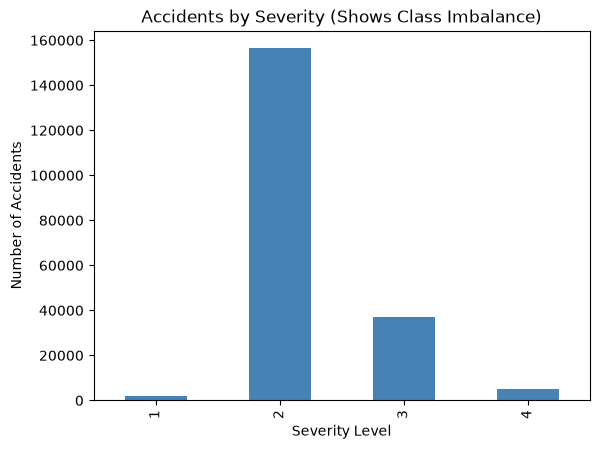

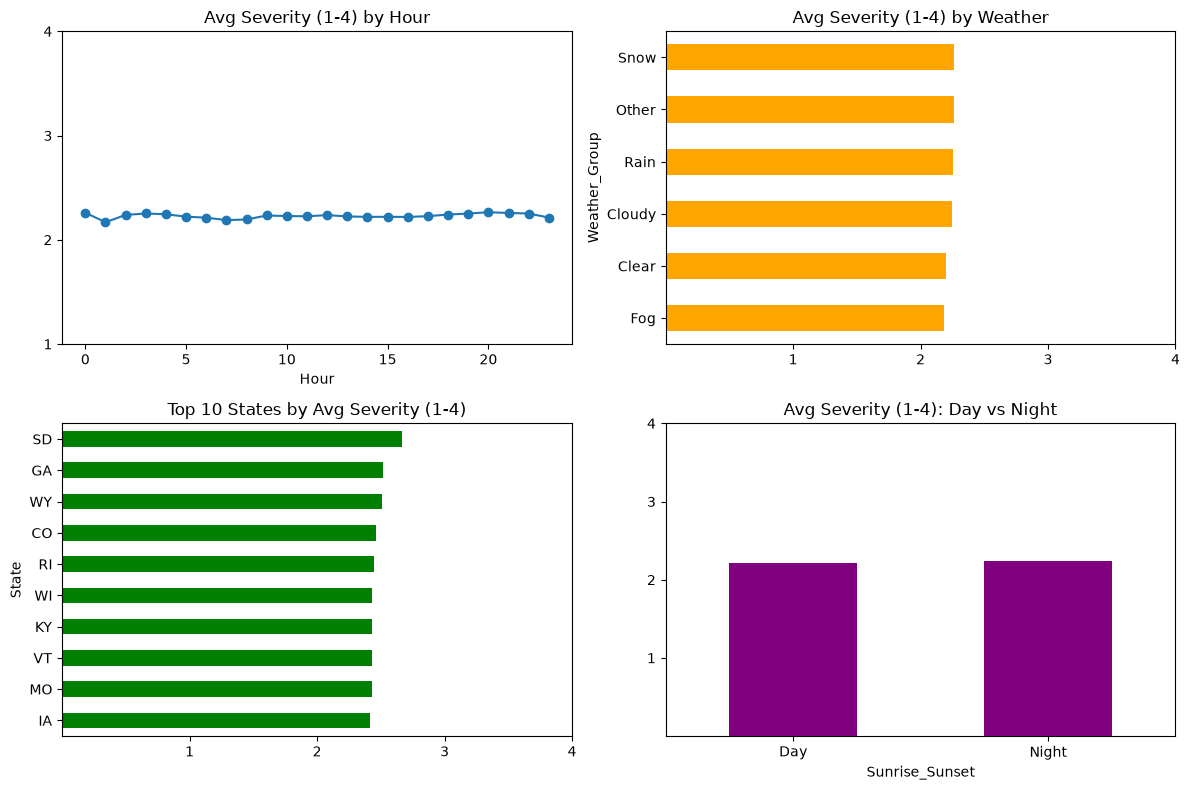

In [12]:
# 4.1 Check Class Imbalance
severity_counts = df["Severity"].value_counts().sort_index()
print("Accident counts per severity:\n", severity_counts)

severity_counts.plot(kind="bar", color="steelblue")
plt.title("Accidents by Severity (Shows Class Imbalance)")
plt.xlabel("Severity Level")
plt.ylabel("Number of Accidents")
plt.show()

# 4.2 Severity Pattern Dashboard (Scale: 1 to 4)
df["Severe"] = (df["Severity"] >= 3).astype(int)  # Kept for Step 10 Lift Analysis
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. By Hour
df.groupby("Hour")["Severity"].mean().plot(ax=axes[0, 0], marker="o", title="Avg Severity (1-4) by Hour")
axes[0, 0].set_yticks([1, 2, 3, 4])

# 2. By Weather
df.groupby("Weather_Group")["Severity"].mean().sort_values().plot(kind="barh", ax=axes[0, 1], color="orange", title="Avg Severity (1-4) by Weather")
axes[0, 1].set_xticks([1, 2, 3, 4])

# 3. Top 10 States
df.groupby("State")["Severity"].mean().sort_values().tail(10).plot(kind="barh", ax=axes[1, 0], color="green", title="Top 10 States by Avg Severity (1-4)")
axes[1, 0].set_xticks([1, 2, 3, 4])

# 4. Day vs Night
df.groupby("Sunrise_Sunset")["Severity"].mean().plot(kind="bar", ax=axes[1, 1], color="purple", rot=0, title="Avg Severity (1-4): Day vs Night")
axes[1, 1].set_yticks([1, 2, 3, 4])

plt.tight_layout()
plt.show()

## Step 5: Feature Engineering

We convert `Weather_Group` into `0`/`1` columns using one-hot encoding (`pd.get_dummies`) and assemble the feature matrix `X` and target `y`. We exclude `State` from `X` so the model learns generalizable road and weather conditions rather than memorizing states.

In [13]:
feature_cols = [
    "Visibility", "Temperature", "Wind_Speed",
    "Hour", "Weekday", "Month",
    "Is_Night", "Junction", "Traffic_Signal", "Crossing"
]

# Convert Weather_Group text into separate 0/1 columns
weather_dummies = pd.get_dummies(df["Weather_Group"], prefix="Weather").astype(int)

# Combine numeric columns and weather columns into X
X = pd.concat([df[feature_cols], weather_dummies], axis=1)
y = df["Severity"]

# Identify the 2 rarest severity classes for minority-class recall
minority_classes = y.value_counts().sort_values().index[:2].tolist()
print("X shape:", X.shape)
print("Minority classes:", minority_classes)

X shape: (200000, 16)
Minority classes: [1, 4]


## Step 6 & 7: Model Selection and Model Training

We train **Naive Bayes**, **Decision Tree**, and **Random Forest** both **without** and **with** class balancing (`class_weight="balanced"` / equal priors) to demonstrate how balancing affects minority-class recall, macro-F1, and accuracy.

In [14]:
# Split 1: Standard Random Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# --- Train UNBALANCED models (to show baseline problem) ---
nb_unbal = GaussianNB()
nb_unbal.fit(X_train, y_train)
pred_nb_unbal = nb_unbal.predict(X_test)

dt_unbal = DecisionTreeClassifier(max_depth=12, min_samples_leaf=30, random_state=42)
dt_unbal.fit(X_train, y_train)
pred_dt_unbal = dt_unbal.predict(X_test)

rf_unbal = RandomForestClassifier(n_estimators=50, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42)
rf_unbal.fit(X_train, y_train)
pred_rf_unbal = rf_unbal.predict(X_test)

# --- Train BALANCED models (handles class imbalance) ---
nb_bal = GaussianNB(priors=[0.25, 0.25, 0.25, 0.25])
nb_bal.fit(X_train, y_train)
pred_nb_bal = nb_bal.predict(X_test)

dt_bal = DecisionTreeClassifier(max_depth=12, min_samples_leaf=30, class_weight="balanced", random_state=42)
dt_bal.fit(X_train, y_train)
pred_dt_bal = dt_bal.predict(X_test)

rf_bal = RandomForestClassifier(n_estimators=50, max_depth=14, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=42)
rf_bal.fit(X_train, y_train)
pred_rf_bal = rf_bal.predict(X_test)

print("All 3 models (unbalanced and balanced) trained successfully.")

All 3 models (unbalanced and balanced) trained successfully.


## Step 8: Model Evaluation & Generalization Testing

We report **Accuracy**, **Macro-F1**, and **Minority-Class Recall**, display normalized confusion matrices, and compare Random Forest generalization across **Random**, **Time** (unseen years), and **State** (unseen states) splits in a single summary table.

**Model Selection Justification:** We select **Random Forest (Balanced)** as our final model for hyperparameter tuning because it achieves the strongest overall balance of **Macro-F1** and **Minority-Class Recall** in the Table 8.1 comparison (and reduces single-tree variance compared to Decision Tree and Naive Bayes).

Table 8.1: Model Comparison (Random Split)
                        Model  Accuracy  Macro-F1  Minority Recall
0    Naive Bayes (Unbalanced)     0.622     0.286            0.200
1      Naive Bayes (Balanced)     0.151     0.132            0.545
2  Decision Tree (Unbalanced)     0.782     0.240            0.004
3    Decision Tree (Balanced)     0.292     0.207            0.535
4  Random Forest (Unbalanced)     0.782     0.221            0.000
5    Random Forest (Balanced)     0.369     0.246            0.521


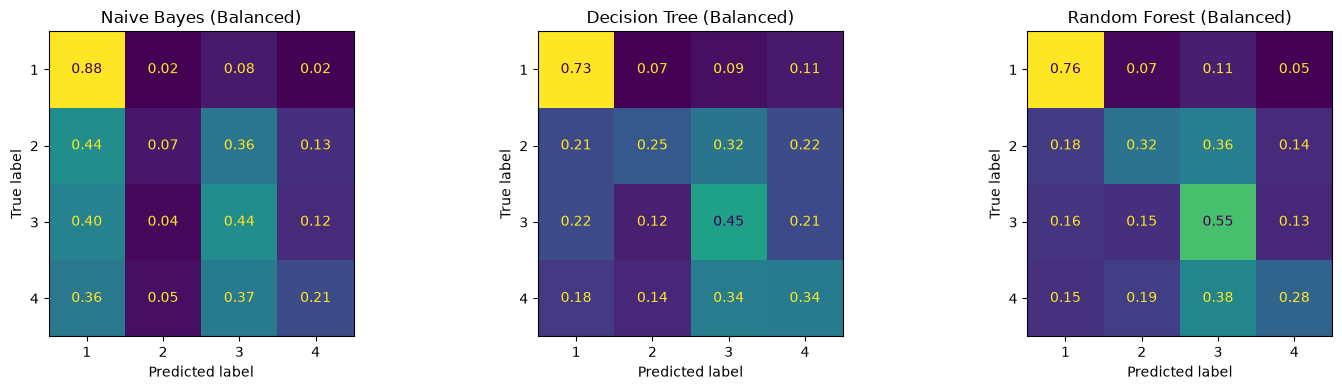


Table 8.2: Random Forest Generalization Across Splits
                         Split  Accuracy  Macro-F1  Minority Recall
0      Random Split (Baseline)     0.369     0.246            0.521
1    Time Split (Unseen Years)     0.289     0.167            0.284
2  State Split (Unseen States)     0.276     0.197            0.432


In [15]:
# 8.1 Compare Unbalanced vs Balanced scores
comparison = []
models_list = [
    ("Naive Bayes (Unbalanced)", pred_nb_unbal),
    ("Naive Bayes (Balanced)", pred_nb_bal),
    ("Decision Tree (Unbalanced)", pred_dt_unbal),
    ("Decision Tree (Balanced)", pred_dt_bal),
    ("Random Forest (Unbalanced)", pred_rf_unbal),
    ("Random Forest (Balanced)", pred_rf_bal),
]

for name, preds in models_list:
    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average="macro")
    min_recall = recall_score(y_test, preds, labels=minority_classes, average="macro", zero_division=0)
    comparison.append({"Model": name, "Accuracy": round(acc, 3), "Macro-F1": round(macro_f1, 3), "Minority Recall": round(min_recall, 3)})

print("Table 8.1: Model Comparison (Random Split)")
print(pd.DataFrame(comparison))

# 8.2 Confusion Matrices for Balanced Models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_nb_bal, normalize="true", values_format=".2f", ax=axes[0], colorbar=False)
axes[0].set_title("Naive Bayes (Balanced)")

ConfusionMatrixDisplay.from_predictions(y_test, pred_dt_bal, normalize="true", values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title("Decision Tree (Balanced)")

ConfusionMatrixDisplay.from_predictions(y_test, pred_rf_bal, normalize="true", values_format=".2f", ax=axes[2], colorbar=False)
axes[2].set_title("Random Forest (Balanced)")

plt.tight_layout()
plt.show()

# 8.3 Generalization Test 1: Unseen Time Period (Last 2 years as test set)
last_year = df["Year"].max()
time_test_mask = df["Year"] >= (last_year - 1)

rf_time = RandomForestClassifier(n_estimators=50, max_depth=14, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=42)
rf_time.fit(X[~time_test_mask], y[~time_test_mask])
pred_time = rf_time.predict(X[time_test_mask])

# 8.4 Generalization Test 2: Unseen States (20% of states held out)
np.random.seed(42)
unique_states = df["State"].unique()
test_states = np.random.choice(unique_states, size=int(0.2 * len(unique_states)), replace=False)
state_test_mask = df["State"].isin(test_states)

rf_state = RandomForestClassifier(n_estimators=50, max_depth=14, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=42)
rf_state.fit(X[~state_test_mask], y[~state_test_mask])
pred_state = rf_state.predict(X[state_test_mask])

# 8.5 Combined Generalization Summary Table (Random vs Time vs State)
gen_table = pd.DataFrame([
    {
        "Split": "Random Split (Baseline)",
        "Accuracy": round(accuracy_score(y_test, pred_rf_bal), 3),
        "Macro-F1": round(f1_score(y_test, pred_rf_bal, average="macro"), 3),
        "Minority Recall": round(recall_score(y_test, pred_rf_bal, labels=minority_classes, average="macro", zero_division=0), 3)
    },
    {
        "Split": "Time Split (Unseen Years)",
        "Accuracy": round(accuracy_score(y[time_test_mask], pred_time), 3),
        "Macro-F1": round(f1_score(y[time_test_mask], pred_time, average="macro"), 3),
        "Minority Recall": round(recall_score(y[time_test_mask], pred_time, labels=minority_classes, average="macro", zero_division=0), 3)
    },
    {
        "Split": "State Split (Unseen States)",
        "Accuracy": round(accuracy_score(y[state_test_mask], pred_state), 3),
        "Macro-F1": round(f1_score(y[state_test_mask], pred_state, average="macro"), 3),
        "Minority Recall": round(recall_score(y[state_test_mask], pred_state, labels=minority_classes, average="macro", zero_division=0), 3)
    }
])

print("\nTable 8.2: Random Forest Generalization Across Splits")
print(gen_table)

## Step 9: Hyperparameter Tuning (`GridSearchCV`)

We tune `RandomForestClassifier` (selected based on our Step 8 comparison) using 3-fold cross-validation optimized for `f1_macro`, then display the confusion matrix and classification report for the final tuned model (`final_pred`).

Best Hyperparameters: {'max_depth': 14, 'min_samples_leaf': 10}
Final Tuned Test Accuracy: 0.369
Final Tuned Test Macro-F1: 0.246
Final Tuned Test Minority Recall: 0.521

Detailed Classification Report:
               precision    recall  f1-score   support

           1       0.04      0.76      0.07       369
           2       0.89      0.32      0.47     31276
           3       0.26      0.55      0.36      7380
           4       0.05      0.28      0.08       975

    accuracy                           0.37     40000
   macro avg       0.31      0.48      0.25     40000
weighted avg       0.74      0.37      0.44     40000



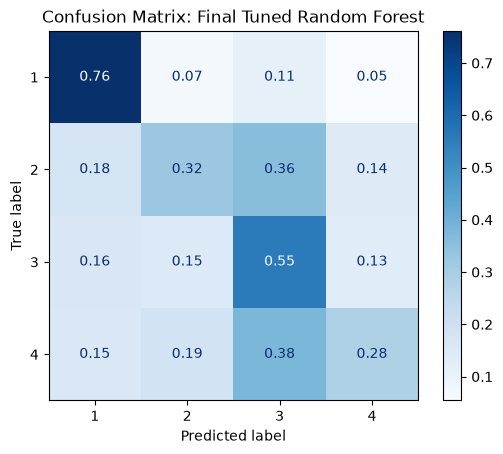

In [16]:
# Tune on a 30,000-row subset of training data so GridSearchCV runs quickly
X_tune = X_train.sample(n=min(30000, len(X_train)), random_state=42)
y_tune = y_train.loc[X_tune.index]

param_grid = {
    "max_depth": [8, 14],
    "min_samples_leaf": [10, 30]
}

rf_base = RandomForestClassifier(n_estimators=50, class_weight="balanced", n_jobs=-1, random_state=42)
grid = GridSearchCV(rf_base, param_grid, cv=3, scoring="f1_macro")
grid.fit(X_tune, y_tune)

print("Best Hyperparameters:", grid.best_params_)

# Train final tuned model on the full training set
final_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=grid.best_params_["max_depth"],
    min_samples_leaf=grid.best_params_["min_samples_leaf"],
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
final_model.fit(X_train, y_train)
final_pred = final_model.predict(X_test)

print("Final Tuned Test Accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("Final Tuned Test Macro-F1:", round(f1_score(y_test, final_pred, average="macro"), 3))
print("Final Tuned Test Minority Recall:", round(recall_score(y_test, final_pred, labels=minority_classes, average="macro", zero_division=0), 3))
print("\nDetailed Classification Report:\n", classification_report(y_test, final_pred, zero_division=0))

# Confusion Matrix for the Final Tuned Model (final_pred)
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, labels=[1, 2, 3, 4], normalize="true", values_format=".2f", cmap="Blues")
plt.title("Confusion Matrix: Final Tuned Random Forest")
plt.show()

## Risk Factor & Error Analysis

1. **Feature Importance:** Shows which features contributed most to Random Forest splits.
2. **Lift Analysis (Table + Chart):** Compares the severe accident rate under each condition against the overall baseline rate (`Lift = 1.0`).
3. **Error Analysis:** Evaluates the **false-alarm rate** (non-severe accidents predicted as severe) and plots **missed severe accidents (%) by both Hour and Weather Condition**.

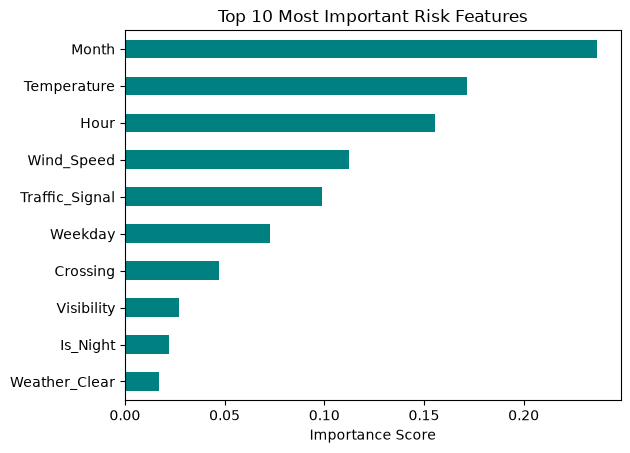


Risk Factor Lift Table:
                  Condition  Severe Rate (%)  Lift
5                 Junction             27.8  1.33
2                     Rain             23.6  1.13
4                     Snow             22.8  1.09
0                    Night             20.6  0.99
1  Low Visibility (< 2 mi)             20.3  0.97
3                      Fog             17.3  0.83
6           Traffic Signal              9.5  0.46


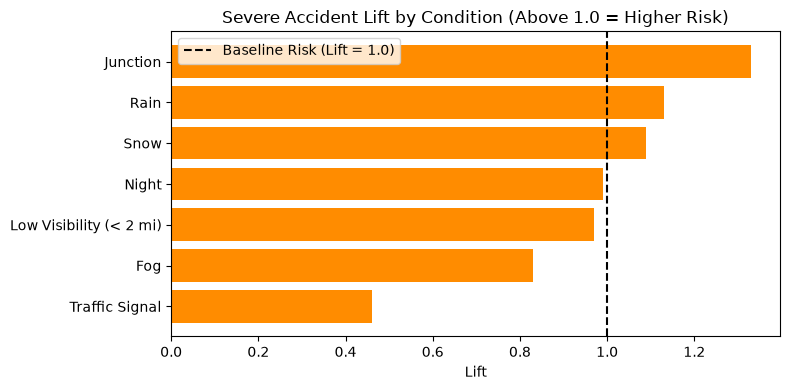


Total real severe accidents in test set: 8355
Missed severe accidents rate: 31.4 %
False-alarm rate (predicted severe, actually minor): 73.2 %


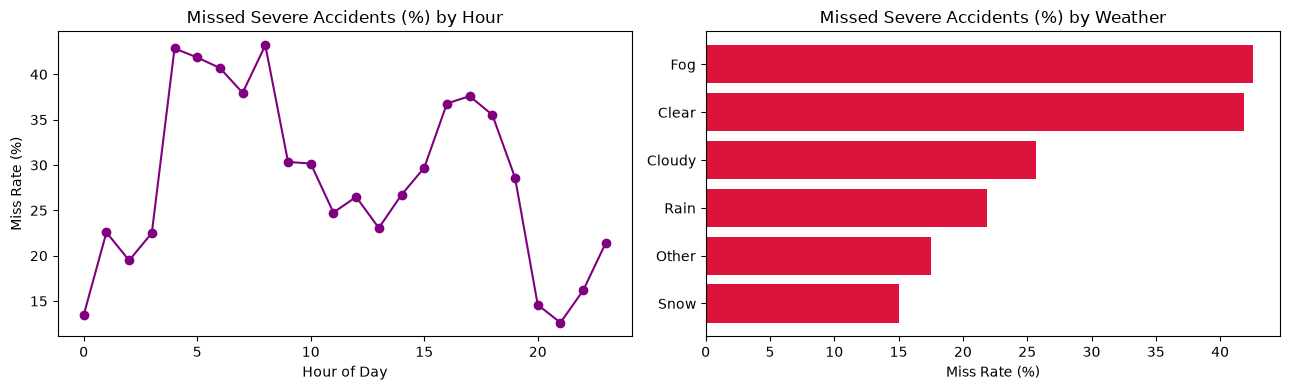

In [17]:
# 1. Feature Importance
importances = pd.Series(final_model.feature_importances_, index=X.columns).sort_values()
importances.tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 Most Important Risk Features")
plt.xlabel("Importance Score")
plt.show()

# 2. Lift Analysis for High-Risk Conditions (Table + Bar Chart with Lift = 1 line)
overall_severe_rate = df["Severe"].mean()

conditions = {
    "Night": df["Is_Night"] == 1,
    "Low Visibility (< 2 mi)": df["Visibility"] < 2,
    "Rain": df["Weather_Group"] == "Rain",
    "Fog": df["Weather_Group"] == "Fog",
    "Snow": df["Weather_Group"] == "Snow",
    "Junction": df["Junction"] == 1,
    "Traffic Signal": df["Traffic_Signal"] == 1
}

lift_rows = []
for cond_name, mask in conditions.items():
    cond_rate = df.loc[mask, "Severe"].mean()
    lift_rows.append({
        "Condition": cond_name,
        "Severe Rate (%)": round(cond_rate * 100, 1),
        "Lift": round(cond_rate / overall_severe_rate, 2)
    })

lift_df = pd.DataFrame(lift_rows).sort_values("Lift", ascending=False)
print("\nRisk Factor Lift Table:\n", lift_df)

# Plot Lift Bar Chart with vertical reference line at 1.0
plt.figure(figsize=(8, 4))
plt.barh(lift_df["Condition"], lift_df["Lift"], color="darkorange")
plt.axvline(1.0, color="black", linestyle="--", label="Baseline Risk (Lift = 1.0)")
plt.gca().invert_yaxis()
plt.title("Severe Accident Lift by Condition (Above 1.0 = Higher Risk)")
plt.xlabel("Lift")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Error Analysis (Misses by Hour, Misses by Weather, and False-Alarm Rate)
error_df = df.loc[y_test.index, ["Hour", "Weather_Group"]].copy()
error_df["Actual"] = y_test
error_df["Predicted"] = final_pred

actual_severe = error_df[error_df["Actual"] >= 3].copy()
actual_severe["Missed"] = (actual_severe["Predicted"] <= 2).astype(int)

predicted_severe = error_df[error_df["Predicted"] >= 3]
false_alarm_rate = (predicted_severe["Actual"] <= 2).mean() * 100

print("\nTotal real severe accidents in test set:", len(actual_severe))
print("Missed severe accidents rate:", round(actual_severe["Missed"].mean() * 100, 1), "%")
print("False-alarm rate (predicted severe, actually minor):", round(false_alarm_rate, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Misses by Hour
miss_by_hour = actual_severe.groupby("Hour")["Missed"].mean() * 100
axes[0].plot(miss_by_hour.index, miss_by_hour.values, marker="o", color="purple")
axes[0].set_title("Missed Severe Accidents (%) by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Miss Rate (%)")

# Misses by Weather
miss_by_weather = (actual_severe.groupby("Weather_Group")["Missed"].mean() * 100).sort_values()
axes[1].barh(miss_by_weather.index, miss_by_weather.values, color="crimson")
axes[1].set_title("Missed Severe Accidents (%) by Weather")
axes[1].set_xlabel("Miss Rate (%)")

plt.tight_layout()
plt.show()

## Step 10: Model Saving & Verification Test

We save the trained model, column order, risk thresholds, and dashboard summary statistics into `roadsafety_model.pkl` so the web backend and URL deployment can load everything cleanly.

In [18]:
# Calculate risk thresholds from predicted severe probabilities (Severity 3 + 4)
probs = final_model.predict_proba(X_test)
classes = list(final_model.classes_)
p_severe = probs[:, classes.index(3)] + probs[:, classes.index(4)]
cutoffs = np.percentile(p_severe, [60, 85])

# Save dashboard statistics for the web frontend
state_counts = df["State"].value_counts()
valid_states = state_counts[state_counts >= 500].index

dashboard_stats = {
    "by_hour": (df.groupby("Hour")["Severe"].mean() * 100).round(1).to_dict(),
    "by_weather": (df.groupby("Weather_Group")["Severe"].mean() * 100).round(1).to_dict(),
    "by_state": (df[df["State"].isin(valid_states)].groupby("State")["Severe"].mean() * 100).round(1).to_dict()
}

saved_bundle = {
    "model": final_model,
    "model_name": "Random Forest (Tuned)",
    "columns": X.columns.tolist(),
    "weather_options": ["Clear", "Cloudy", "Rain", "Fog", "Snow", "Other"],
    "risk_cutoffs": cutoffs.tolist(),
    "stats": dashboard_stats,
    "sklearn_version": sklearn.__version__
}

joblib.dump(saved_bundle, "roadsafety_model.pkl", compress=3)
print("Saved roadsafety_model.pkl successfully!")

# Quick test loading the file and predicting a single sample
loaded = joblib.load("roadsafety_model.pkl")
sample_input = pd.DataFrame([{
    "Visibility": 1, "Temperature": 45, "Wind_Speed": 8,
    "Hour": 23, "Weekday": 5, "Month": 11, "Is_Night": 1,
    "Junction": 1, "Traffic_Signal": 0, "Crossing": 0, "Weather_Fog": 1
}])
sample_input = sample_input.reindex(columns=loaded["columns"], fill_value=0)

sample_prob = loaded["model"].predict_proba(sample_input)[0]
severe_chance = sample_prob[classes.index(3)] + sample_prob[classes.index(4)]
print("Test Prediction - Severe Accident Probability:", round(severe_chance * 100, 1), "%")

Saved roadsafety_model.pkl successfully!
Test Prediction - Severe Accident Probability: 62.2 %
